# 01 · Data Exploration

Human Activity Recognition using Hidden Markov Models.

We recorded four activities (**standing**, **walking**, **jumping**, **still**) with
the *Sensor Logger* app on an iPhone 11 Pro: accelerometer and gyroscope, 3 axes each,
at 100 Hz. The procedure is in [`docs/collection_protocol.md`](../docs/collection_protocol.md).

The training data (`data/raw/`, 65 recordings) comes from three sessions:

| Session | Recordings | Raw length | Indices |
|---|---|---|---|
| 29 Oct | 16 (4 per activity) | 8–12 s | `_01`–`_04` |
| 31 Oct – 1 Nov midday | 29 | 4.6–7 s | `_05`–`_12` (jumping `_05`–`_09`) |
| 1 Nov afternoon | 20 | 6.4–7.8 s | standing `_13`–`_16`, still `_13`–`_19`, walking `_13`–`_17`, jumping `_10`–`_13` |

Two more recordings from a fourth session are kept apart in `data/test/` as **unseen test data**
(see notebook 04). They are not used here or in training.

This notebook checks what we collected before any modeling.

In [1]:
# --- Environment setup (works locally and in Google Colab) ---
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/Orrie-Dan/Human-Activity-HMM.git"
    ROOT = Path("/content/human-activity-hmm")
    if not ROOT.exists():
        !git clone -q {REPO_URL} {ROOT}
    %cd {ROOT}
    !pip install -q -r requirements.txt
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# The recordings are in the repository (data/raw/, data/test/). Fallback only: if
# data/raw/ is empty in Colab, upload a zip of its contents (p01_<activity>_<nn>/ + metadata.csv).
RAW = ROOT / "data" / "raw"
if IN_COLAB and not any(RAW.glob("p*_*_*")):
    import io, zipfile
    from google.colab import files
    for name, content in files.upload().items():
        zipfile.ZipFile(io.BytesIO(content)).extractall(RAW)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.visualization import apply_style

apply_style()
pd.set_option("display.precision", 3)


## Load raw data

Each recording is a folder `p01_<activity>_<nn>/` with one CSV per sensor. `metadata.csv` logs the device, app and notes for every recording.

In [3]:
from src.data_loader import find_recordings, load_recording, parse_recording_name

recordings = find_recordings()
metadata = pd.read_csv(config.RAW_DATA_DIR / "metadata.csv")
print(f"{len(recordings)} recordings found")
metadata

65 recordings found


,recording,participant,activity,source,phone_model,os,app,sampling_rate_hz,placement,notes
0,p01_jumping_01,p01,jumping,Jumping-2026-10-29_11-30-08.zip,iPhone 11 Pro,ios 18.7.8,Sensor Logger 1.68,100,NaN,NaN
1,p01_jumping_02,p01,jumping,jumping-2026-10-29_17-21-08.zip,iPhone 11 Pro,ios 18.7.8,Sensor Logger 1.68,100,NaN,NaN
2,p01_jumping_03,p01,jumping,jumping-2026-10-29_17-21-24.zip,iPhone 11 Pro,ios 18.7.8,Sensor Logger 1.68,100,NaN,NaN
3,p01_jumping_04,p01,jumping,jumping-2026-10-29_17-21-39.zip,iPhone 11 Pro,ios 18.7.8,Sensor Logger 1.68,100,NaN,NaN
4,p01_jumping_05,p01,jumping,jumping-2026-10-31_21-27-32.zip,iPhone 11 Pro,ios 18.7.8,Sensor Logger 1.68,100,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
60,p01_walking_17,p01,walking,walking-2026-11-01_15-21-36.zip,iPhone 11 Pro,ios 18.7.8,Sensor Logger 1.68,100,NaN,NaN
61,p01_jumping_10,p01,jumping,jumping-2026-11-01_15-45-19.zip,iPhone 11 Pro,ios 18.7.8,Sensor Logger 1.68,100,NaN,NaN
62,p01_jumping_11,p01,jumping,jumping-2026-11-01_15-45-30.zip,iPhone 11 Pro,ios 18.7.8,Sensor Logger 1.68,100,NaN,NaN
63,p01_jumping_12,p01,jumping,jumping-2026-11-01_15-45-41.zip,iPhone 11 Pro,ios 18.7.8,Sensor Logger 1.68,100,NaN,NaN


## Inspect signals per activity

First, every recording's raw length and sampling rate, and whether it passes validation after the 1 s trim at each end.

In [4]:
from src.preprocessing import trim, validate_recording

rows = []
for rec in recordings:
    info = parse_recording_name(rec)
    acc, gyro = load_recording(rec)
    raw = validate_recording(acc)
    trimmed = validate_recording(trim(acc))
    rows.append({
        "recording": rec.name, "activity": info.activity,
        "raw_samples": raw.n_samples, "raw_duration_s": raw.duration_s,
        "rate_hz": raw.sampling_rate_hz, "trimmed_duration_s": trimmed.duration_s,
        "valid": trimmed.is_valid and validate_recording(trim(gyro)).is_valid,
    })
summary = pd.DataFrame(rows)
summary

,recording,activity,raw_samples,raw_duration_s,rate_hz,trimmed_duration_s,valid
0,p01_jumping_01,jumping,915,9.159,99.798,7.155,True
1,p01_jumping_02,jumping,1129,11.305,99.781,9.300,True
2,p01_jumping_03,jumping,1031,10.322,99.781,8.318,True
3,p01_jumping_04,jumping,960,9.611,99.781,7.607,True
4,p01_jumping_05,jumping,563,5.632,99.788,3.628,True
...,...,...,...,...,...,...,...
60,p01_walking_13,walking,724,7.245,99.788,5.241,True
61,p01_walking_14,walking,777,7.776,99.793,5.772,True
62,p01_walking_15,walking,734,7.345,99.793,5.341,True
63,p01_walking_16,walking,781,7.816,99.793,5.812,True


Below is one recording per activity after trimming and resampling to 50 Hz. We show the **magnitude** of acceleration and rotation rate, which does not depend on how the phone is oriented in the hand.

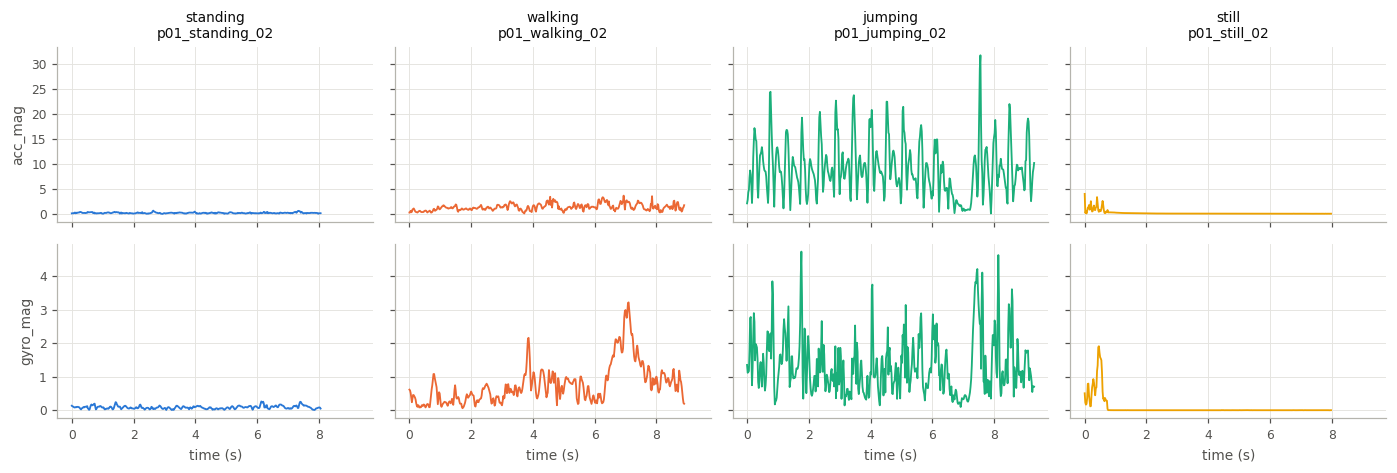

In [5]:
from src.dataset import process_recording
from src.features import add_magnitudes
from src.visualization import plot_signals

examples = {f"p01_{a}_02": a for a in config.ACTIVITIES}
signals = {name: add_magnitudes(process_recording(config.RAW_DATA_DIR / name)) for name in examples}
plot_signals(signals, labels=examples);

The four activities look very different:

- **jumping** has large, frequent spikes of up to about 30 m/s².
- **walking** is periodic at a much lower amplitude.
- **standing** is small, irregular hand tremor.
- **still** is essentially flat. The phone lies on a table.

Note that Sensor Logger's `Accelerometer.csv` on iOS is *user acceleration*, with gravity
removed. That is why still sits near 0 rather than 9.81.

### Recording artifacts

While importing, we flagged five recordings with handling artifacts (see the `notes` column above). Four are shown below. The shaded regions are removed by the 1 s trim.

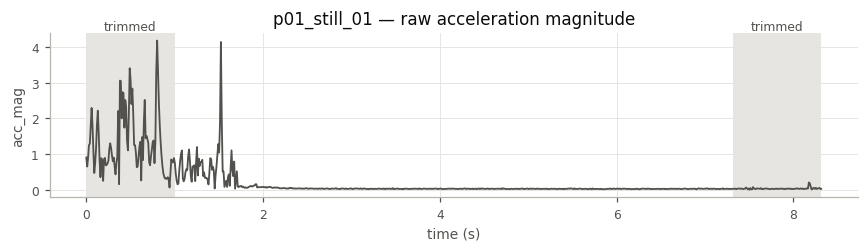

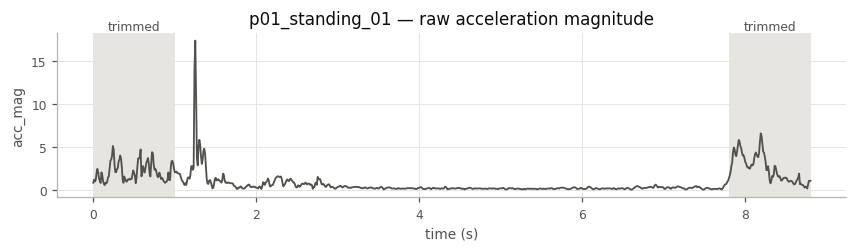

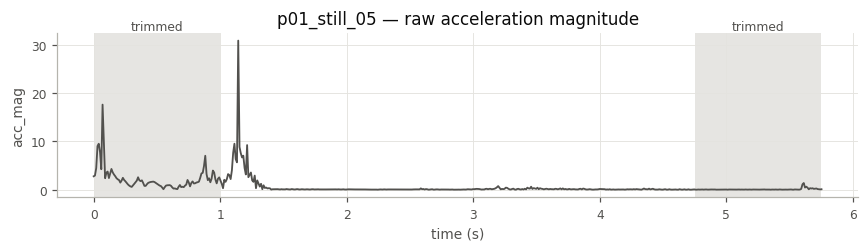

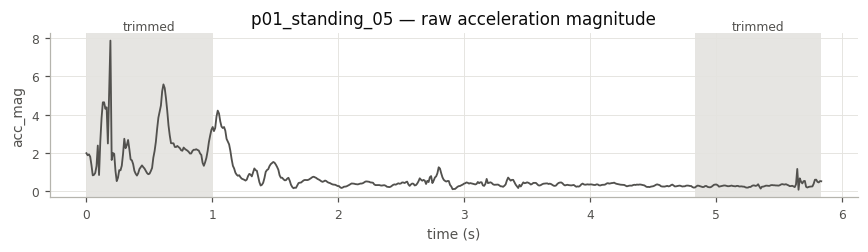

In [6]:
from src.visualization import plot_trim

for name in ["p01_still_01", "p01_standing_01", "p01_still_05", "p01_standing_05"]:
    acc, _ = load_recording(config.RAW_DATA_DIR / name)
    acc["acc_mag"] = np.linalg.norm(acc[list(config.ACCELEROMETER_COLUMNS)], axis=1)
    plot_trim(acc, "acc_mag", f"{name} — raw acceleration magnitude")
    plt.show()

- `p01_still_01` (and `_02`) and `p01_still_05` show the phone being put down. The movement
  lasts longer than 1 s, so some of it remains after trimming. In `_05` the largest spike
  (about 30 m/s²) comes just after the trimmed region.
- `p01_standing_05` has handling until about 1.3 s.
- `p01_standing_01` has a large spike in the middle, probably a bump. Trimming the ends cannot
  remove it.

We keep these recordings. They are realistic noise, and we follow up on them in the evaluation.

## Class balance and sampling rate

In [7]:
summary.groupby("activity").agg(
    recordings=("recording", "count"),
    total_seconds=("trimmed_duration_s", "sum"),
    mean_rate_hz=("rate_hz", "mean"),
)

,recordings,total_seconds,mean_rate_hz
activity,,,
jumping,13,72.151,99.792
standing,16,80.130,99.787
still,19,99.271,99.788
walking,17,93.201,99.785


Every activity has 13–19 recordings. In raw recording time that is **98 s (jumping), 112 s
(standing), 137 s (still) and 127 s (walking)**, so each activity has more than the required
1 min 30 s. The table above shows the time left after the 1 s trim at each end: 72–99 s per
activity. The classes are reasonably balanced; jumping has the least data.

**Sampling rate.** All data was recorded on one phone (iPhone 11 Pro,
Sensor Logger 1.68, set to 100 Hz). The measured rate is 99.8 Hz for every activity. Sensor
Logger samples the accelerometer and gyroscope at slightly different instants, and other phones
or apps report at other rates (often 50, 100 or 200 Hz). The pipeline therefore never relies on
the raw rate: it checks that each stream is at least 50 Hz and then **linearly interpolates both
sensors onto one shared 50 Hz grid** (notebook 02). A recording from a different phone would go
through the same step.

The short recordings (4.6–7.8 s in the app) keep only 2.6–5.8 s after trimming. That is why the
pipeline accepts trimmed recordings down to 2 s (one feature window). `p01_standing_08`
(4.65 s raw) is slightly below the assignment's 5 s guideline.